# Bidomain counts across datasets (mivia, lv, bi)

Reads the merged `*_with_ref_all.csv` files from the HPC and compares per-search **mean** and **max** bidomain counts across datasets, plus the fidelity of the unified reimplementation against the reference.

**How to use:** edit the config cell below (folder, algorithms, datasets), then *Run All*.
Expected filename: `{algo}_{dataset}_with_ref_all.csv`, with the 21-column header
(`instance_a,...,unified_bidomain_mean,unified_bidomain_max,ref_size,ref_nodes,ref_time,ref_bidomain_mean,ref_bidomain_max,match`).

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- CONFIG ----------------
DATA_DIR = Path("hpc/publication/results")   # forward slashes; relative paths are searched upwards from the notebook's folder
ALGOS    = ["mcsplit"]                       # first one is the main baseline (add e.g. "rl_pair" for the robustness plots)
DATASETS = ["mivia", "lv", "bi"]
MIN_SOLUTION_SIZE = 0                      # set e.g. 5 to drop tiny instances (leaf nodes pull the mean down)
USE_REF_SIDE = False                       # True = plot the reference's bidomain stats instead of the unified ones
# ----------------------------------------

# Resolve DATA_DIR: if it is relative, look for it in the current folder and every parent folder,
# so it works whether Jupyter was started in the repo root, a notebooks/ subfolder, or elsewhere.
if not DATA_DIR.is_absolute():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / DATA_DIR).exists():
            DATA_DIR = base / DATA_DIR
            break
print("running from:", Path.cwd())
print("data folder: ", DATA_DIR.resolve(), "| exists:", DATA_DIR.exists())
if DATA_DIR.exists():
    print("csv files:   ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

COLUMNS = ["instance_a","instance_b","algo","unified_size","unified_edges","unified_nodes",
           "unified_time","unified_aborted","unified_nodes_to_best","unified_time_to_best",
           "unified_cut_branches","unified_bound_pruned","unified_sym_pruned",
           "unified_bidomain_mean","unified_bidomain_max","ref_size","ref_nodes","ref_time",
           "ref_bidomain_mean","ref_bidomain_max","match"]
NUMERIC = [c for c in COLUMNS if c not in ("instance_a","instance_b","algo","match")]

def load(algo, ds):
    path = DATA_DIR / f"{algo}_{ds}_with_ref_all.csv"
    if not path.exists():
        print(f"missing: {path.name}")
        return None
    df = pd.read_csv(path)
    # tolerate a file saved without a header row
    if "unified_nodes" not in df.columns:
        df = pd.read_csv(path, header=None, names=COLUMNS)
    for c in NUMERIC:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df["dataset"] = ds
    df["algo_name"] = algo
    return df

frames = [load(a, d) for a in ALGOS for d in DATASETS]
frames = [f for f in frames if f is not None]
assert frames, "No files found - check DATA_DIR / ALGOS / DATASETS"
data = pd.concat(frames, ignore_index=True)
data = data[data["unified_size"].fillna(0) >= MIN_SOLUTION_SIZE].copy()

pref = "ref" if USE_REF_SIDE else "unified"
data["bd_mean"] = data[f"{pref}_bidomain_mean"]
data["bd_max"]  = data[f"{pref}_bidomain_max"]
# fidelity helpers
data["node_exact"] = data["unified_nodes"] == data["ref_nodes"]
data["node_ratio"] = data["ref_nodes"] / data["unified_nodes"]
print(data.groupby(["algo_name","dataset"]).size().rename("pairs").to_frame())

running from: c:\Users\Tara Relan\Documents\GitHub\mcsplit-unified-framework\evaluation\scripts
data folder:  C:\Users\Tara Relan\Documents\GitHub\mcsplit-unified-framework\hpc\publication\results | exists: True
csv files:    ['dal_bi_with_ref_all.csv', 'down_mivia_with_ref_all.csv', 'dsb_bi_with_ref_all.csv', 'll_bi_with_ref_all.csv', 'mcsplit_bi_with_ref_all.csv', 'mcsplit_lv_with_ref_all.csv', 'mcsplit_mivia_with_ref_all.csv', 'rl_bi_with_ref_all.csv', 'rl_down_bi_with_ref_all.csv', 'rl_down_lv_with_ref_all.csv', 'rl_down_mivia_with_ref_all.csv', 'rl_pair_bi_with_ref_all.csv', 'rl_pair_lv_with_ref_all.csv', 'rl_pair_mivia_with_ref_all.csv', 'rl_rate_bi_with_ref_all.csv', 'rl_rate_lv_with_ref_all.csv', 'rl_rate_mivia_with_ref_all.csv', 'rrsplit_bi_with_ref_all.csv', 'symsplit_bi_with_ref_all.csv']
                   pairs
algo_name dataset       
mcsplit   bi        9135
          lv        6100
          mivia     8131


## 1. Summary table

In [13]:
def q(p):
    return lambda s: s.quantile(p)

summary = (data.groupby(["algo_name","dataset"])
    .agg(pairs=("bd_mean","size"),
         mean_of_mean=("bd_mean","mean"), median_of_mean=("bd_mean","median"),
         p90_of_mean=("bd_mean", q(0.9)),
         mean_of_max=("bd_max","mean"), median_of_max=("bd_max","median"),
         largest_max=("bd_max","max"),
         median_solution_size=("unified_size","median"))
    .round(3))
summary

pairs  mean_of_mean  median_of_mean  p90_of_mean  \
algo_name dataset                                                     
mcsplit   bi        9135         2.289           2.218        3.102   
          lv        6100         2.635           1.984        4.887   
          mivia     8131         4.155           3.764        6.308   

                   mean_of_max  median_of_max  largest_max  \
algo_name dataset                                            
mcsplit   bi             6.478            6.0         48.0   
          lv            12.579            8.0        973.0   
          mivia         14.064           13.0         75.0   

                   median_solution_size  
algo_name dataset                        
mcsplit   bi                       18.0  
          lv                       40.0  
          mivia                    32.0

## 2. Histograms of the per-pair **mean** bidomain count
Density-normalised with shared bins, so the shapes are comparable even though the datasets have different numbers of pairs.

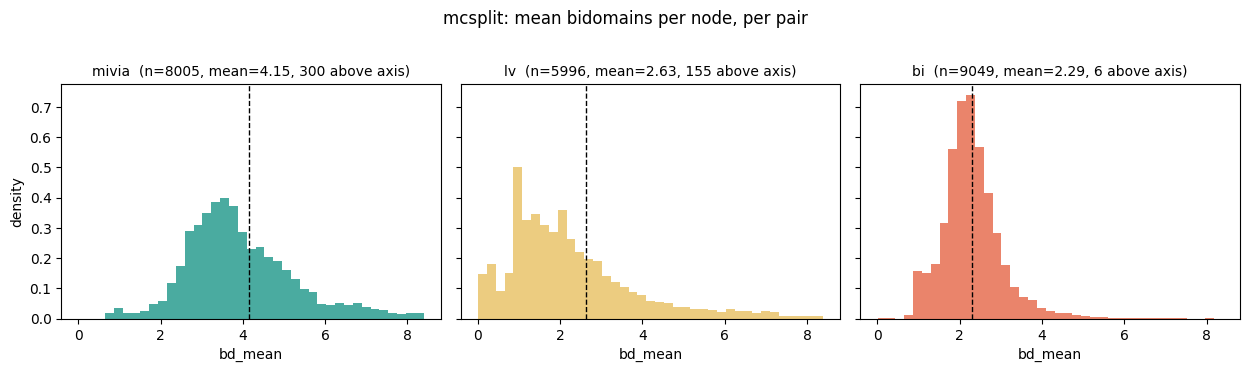

In [14]:
COLORS = {"mivia":"#2a9d8f", "lv":"#e9c46a", "bi":"#e76f51"}

def hist_by_dataset(df, col, title, bins=40, logx=False, clip_pct=98):
    """Histogram per dataset. A few extreme pairs can stretch the x-axis so far that every
    bar is squashed into one, so the axis stops at the clip_pct percentile of all pairs
    (pairs above it are left out of the bars; the count is shown in each title). Set clip_pct=100 to see everything."""
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.2*len(DATASETS), 3.6), sharex=True, sharey=True)
    axes = np.atleast_1d(axes)
    vals = df[col].dropna()
    hi = np.percentile(vals, clip_pct)
    lo = max(vals.min(), 1e-2) if logx else vals.min()
    edges = np.logspace(np.log10(lo), np.log10(hi), bins) if logx else np.linspace(lo, hi, bins)
    for ax, ds in zip(axes, DATASETS):
        s = df.loc[df["dataset"]==ds, col].dropna()
        ax.hist(s[s <= hi], bins=edges, density=True, color=COLORS.get(ds,"grey"), alpha=0.85)
        if len(s):
            ax.axvline(s.mean(), color="black", ls="--", lw=1)
            n_above = int((s > hi).sum())
            extra = f", {n_above} above axis" if n_above else ""
            ax.set_title(f"{ds}  (n={len(s)}, mean={s.mean():.2f}{extra})", fontsize=10)
        else:
            ax.set_title(f"{ds} (no data)", fontsize=10)
        if logx: ax.set_xscale("log")
        ax.set_xlabel(col)
    axes[0].set_ylabel("density")
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    return fig

base = data[data["algo_name"]==ALGOS[0]]
hist_by_dataset(base, "bd_mean", f"{ALGOS[0]}: mean bidomains per node, per pair");

## 3. Histograms of the per-pair **max** bidomain count

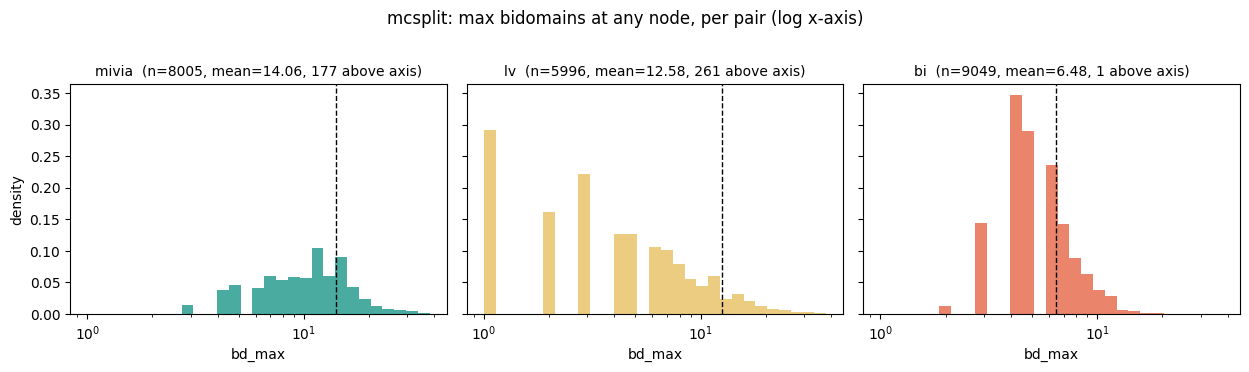

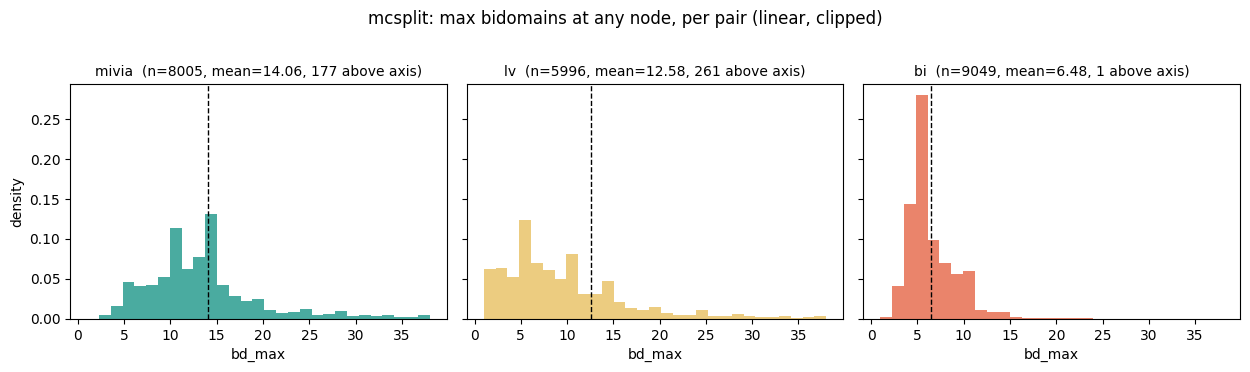

In [15]:
hist_by_dataset(base, "bd_max", f"{ALGOS[0]}: max bidomains at any node, per pair (log x-axis)", bins=30, logx=True)
hist_by_dataset(base, "bd_max", f"{ALGOS[0]}: max bidomains at any node, per pair (linear, clipped)", bins=30);

## 4. Control for instance size
Bidomain counts grow with graph size, so a difference between datasets could just be a size difference. This plots the mean against solution size (the only size measure in the CSV) for each dataset.

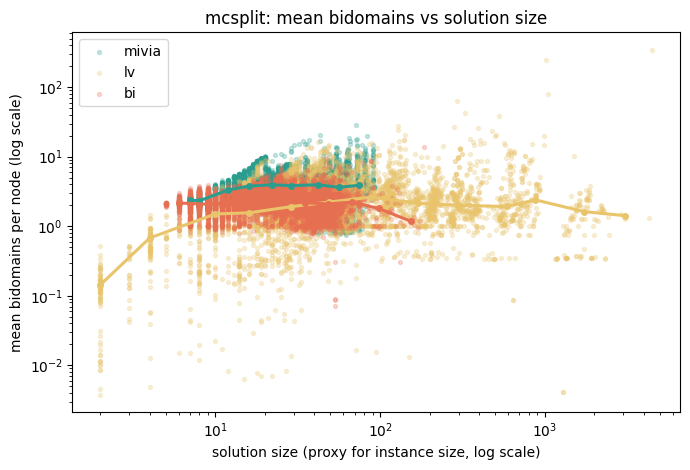

In [24]:
fig, ax = plt.subplots(figsize=(7, 4.8))
for ds in DATASETS:
    s = base[(base["dataset"]==ds) & (base["unified_size"]>0) & (base["bd_mean"]>0)]   # log axes can't show zeros
    ax.scatter(s["unified_size"], s["bd_mean"], s=8, alpha=0.25, label=ds, color=COLORS.get(ds,"grey"))
    # median line per size bin, so the trend is readable through the cloud of points
    edges = np.logspace(0, np.log10(s["unified_size"].max()+1), 15)
    mid = s.groupby(pd.cut(s["unified_size"], edges), observed=True).agg(
        x=("unified_size","median"), y=("bd_mean","median"), n=("bd_mean","size"))
    mid = mid[mid["n"] >= 5]
    ax.plot(mid["x"], mid["y"], color=COLORS.get(ds,"grey"), lw=2.2, marker="o", ms=4)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("solution size (proxy for instance size, log scale)")
ax.set_ylabel("mean bidomains per node (log scale)")
ax.set_title(f"{ALGOS[0]}: mean bidomains vs solution size")
ax.legend()
fig.tight_layout();

In [17]:
# Same comparison inside solution-size buckets
bins = [0, 5, 10, 15, 20, 30, 1000]
base_b = base.copy()
base_b["size_bucket"] = pd.cut(base_b["unified_size"], bins=bins, right=False)
(base_b.pivot_table(index="size_bucket", columns="dataset", values="bd_mean",
                    aggfunc=["mean","count"], observed=True).round(2))

mean               count                
dataset        bi    lv mivia      bi      lv   mivia
size_bucket                                          
[0, 5)        NaN  0.33   NaN     NaN   167.0     NaN
[5, 10)      2.12  1.46  2.33  1575.0   280.0   282.0
[10, 15)     2.19  1.43  3.56  1639.0   449.0   598.0
[15, 20)     2.49  2.44  4.85  1686.0   307.0  1030.0
[20, 30)     2.46  2.20  4.36  1562.0   840.0  1786.0
[30, 1000)   2.23  2.93  4.11  2587.0  3846.0  4309.0

## 5. ECDF (easier to compare than overlapping histograms)

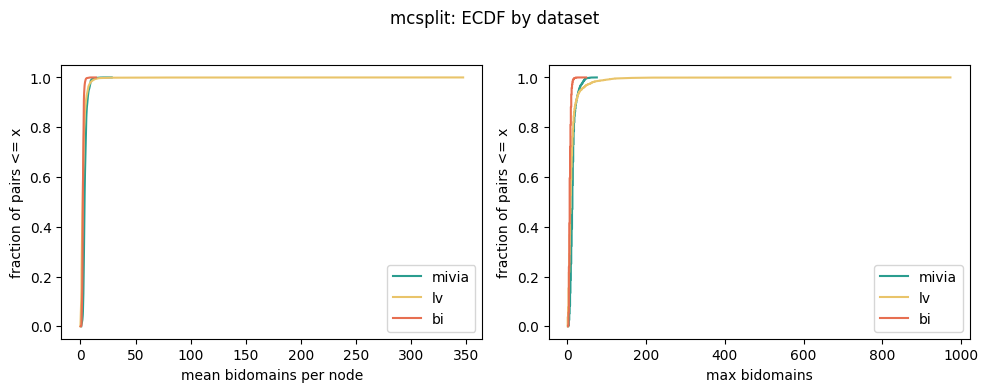

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, lab in zip(axes, ["bd_mean","bd_max"], ["mean bidomains per node","max bidomains"]):
    for ds in DATASETS:
        s = np.sort(base.loc[base["dataset"]==ds, col].dropna().values)
        if len(s):
            ax.plot(s, np.arange(1, len(s)+1)/len(s), label=ds, color=COLORS.get(ds,"grey"))
    ax.set_xlabel(lab); ax.set_ylabel("fraction of pairs <= x"); ax.legend()
fig.suptitle(f"{ALGOS[0]}: ECDF by dataset", y=1.02)
fig.tight_layout();

## 6. Robustness: does a second algorithm show the same pattern?
Mean-of-means per dataset for every algorithm loaded.

In [19]:
(data.pivot_table(index="algo_name", columns="dataset", values="bd_mean", aggfunc="mean")
     .reindex(columns=DATASETS).round(3))

dataset,mivia,lv,bi
algo_name,,,
mcsplit,4.155,2.635,2.289


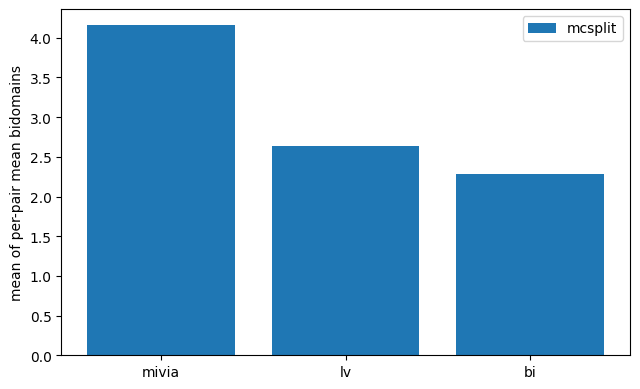

In [20]:
fig, ax = plt.subplots(figsize=(6.5, 4))
width = 0.8 / max(len(ALGOS),1)
for i, a in enumerate(ALGOS):
    vals = [data[(data.algo_name==a)&(data.dataset==d)]["bd_mean"].mean() for d in DATASETS]
    ax.bar(np.arange(len(DATASETS)) + i*width, vals, width, label=a)
ax.set_xticks(np.arange(len(DATASETS)) + width*(len(ALGOS)-1)/2); ax.set_xticklabels(DATASETS)
ax.set_ylabel("mean of per-pair mean bidomains"); ax.legend()
fig.tight_layout();

## 7. Fidelity per dataset (unified vs reference)
Solution-size agreement, how often node counts match exactly, and how large the node-count gap is when they do not.

In [21]:
def fid(g):
    return pd.Series({
        "pairs": len(g),
        "size_match_rate": (g["match"]=="PASS").mean(),
        "exact_node_match_rate": g["node_exact"].mean(),
        "median_node_ratio(ref/unified)": g["node_ratio"].replace([np.inf,-np.inf], np.nan).median(),
        "p90_node_ratio": g["node_ratio"].replace([np.inf,-np.inf], np.nan).quantile(0.9),
        "abs_node_diff_max": (g["unified_nodes"]-g["ref_nodes"]).abs().max(),
    })

fidelity = data.groupby(["algo_name","dataset"]).apply(fid, include_groups=False).round(3)
fidelity

pairs  size_match_rate  exact_node_match_rate  \
algo_name dataset                                                   
mcsplit   bi       9135.0            0.717                  0.078   
          lv       6100.0            0.169                  0.100   
          mivia    8131.0            0.502                  0.475   

                   median_node_ratio(ref/unified)  p90_node_ratio  \
algo_name dataset                                                   
mcsplit   bi                                1.078         393.045   
          lv                                1.000           1.002   
          mivia                             1.000           1.000   

                   abs_node_diff_max  
algo_name dataset                     
mcsplit   bi            3.116818e+10  
          lv            7.675584e+09  
          mivia         4.892913e+08

## 8. Fidelity vs bidomain count
Does a higher mean bidomain count go with a larger node-count gap? (log of the ratio, so 0 = identical.)

,algo,dataset,n,"spearman(bd_mean, |log ratio|)"
0,mcsplit,bi,6498,-0.091
1,mcsplit,lv,928,-0.441
2,mcsplit,mivia,3954,-0.167


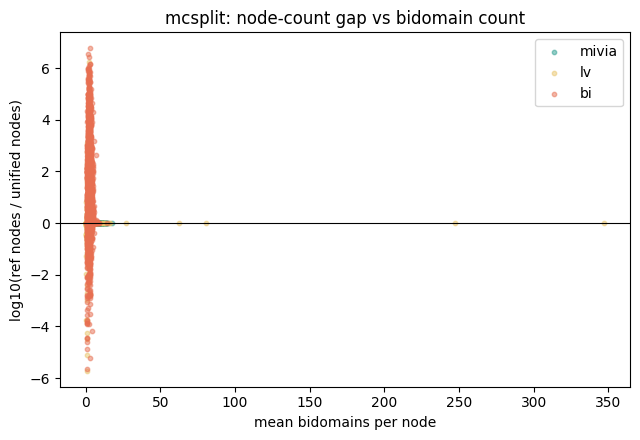

In [22]:
d = data.replace([np.inf,-np.inf], np.nan).dropna(subset=["bd_mean","node_ratio"]).copy()
d = d[d["node_ratio"] > 0]
d["log10_ratio"] = np.log10(d["node_ratio"])

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for ds in DATASETS:
    s = d[(d["dataset"]==ds)&(d["algo_name"]==ALGOS[0])]
    ax.scatter(s["bd_mean"], s["log10_ratio"], s=10, alpha=0.5, label=ds, color=COLORS.get(ds,"grey"))
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("mean bidomains per node"); ax.set_ylabel("log10(ref nodes / unified nodes)")
ax.set_title(f"{ALGOS[0]}: node-count gap vs bidomain count"); ax.legend()
fig.tight_layout()

# Spearman correlation per dataset (rank-based, robust to outliers)
rows = []
for (a, ds), g in d.groupby(["algo_name","dataset"]):
    if len(g) > 2:
        rows.append({"algo": a, "dataset": ds, "n": len(g),
                     "spearman(bd_mean, |log ratio|)": g["bd_mean"].corr(g["log10_ratio"].abs(), method="spearman")})
pd.DataFrame(rows).round(3)

## 9. Sanity check: unified vs reference bidomain stats
These should lie on the diagonal if the instrumentation is consistent on both sides.

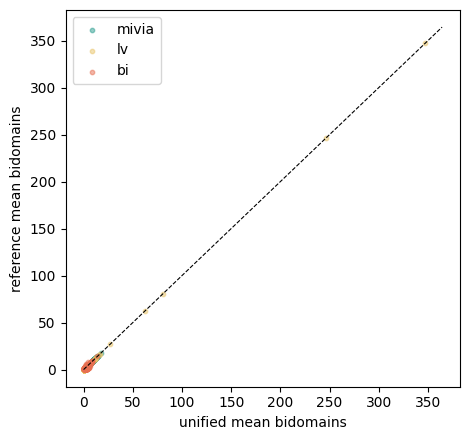

In [23]:
fig, ax = plt.subplots(figsize=(4.8, 4.5))
s = data[data["algo_name"]==ALGOS[0]]
for ds in DATASETS:
    t = s[s["dataset"]==ds]
    ax.scatter(t["unified_bidomain_mean"], t["ref_bidomain_mean"], s=10, alpha=0.5, label=ds, color=COLORS.get(ds,"grey"))
lim = [0, max(s["unified_bidomain_mean"].max(), s["ref_bidomain_mean"].max())*1.05]
ax.plot(lim, lim, "k--", lw=0.8)
ax.set_xlabel("unified mean bidomains"); ax.set_ylabel("reference mean bidomains"); ax.legend()
fig.tight_layout();